# Module 7 ? Model Monitoring

BaBank: fixed training references, persistent monitoring history, delayed labels, drift/performance rules and retraining recommendations.

**Scope:** these are controlled study replays over the saved Module 5 model. Dates are synthetic; they are not observed bank operations. The 1,000 held-out test customers are reused across scenarios and split into two disjoint 500-customer windows within each scenario.

## Data and model provenance

The original Module 5 training cohort supplies numeric bins, categorical distributions and prediction reference distributions before SMOTE. The saved JSON checkpoint is unchanged. Its six test metrics were reproduced when preparing preprocessing. Reports retain checkpoint/preprocessor/reference identities, policy hash, source, scenario and window boundaries. Live, fixed snapshot batch and study replay are isolated.

In [1]:
from pathlib import Path
import json
import pandas as pd
root = Path.cwd()
if not (root / "monitoring").exists():
    root = root.parent
report_dir = root / "artifacts/monitoring/reports"
reports = [json.loads(path.read_text(encoding="utf-8")) for path in sorted(report_dir.glob("*.json"))]
reports = [report for report in reports if "drift" in report]
if not reports:
    raise RuntimeError("Generate/export monitoring reports first; see docs/module-7-monitoring.md")
rows = [{"scenario":r["scenario"],"window":r["window_start"][:10],"samples":r["sample_count"],
         "drift_share":r["drift"]["critical_share"],"average_precision":r["performance"]["metrics"]["average_precision"],"status":r["status"]} for r in reports]
summary = pd.DataFrame(rows)
summary


scenario,window,samples,drift_share,average_precision,status
behavior_drift,2026-08-15,500,0.333333,0.610172,critical
behavior_drift,2026-08-16,500,0.333333,0.607014,review_required
performance_drop,2026-08-15,500,0.000000,0.307852,warning
performance_drop,2026-08-16,500,0.000000,0.307858,retraining_required
stable,2026-08-15,500,0.000000,0.607298,stable
stable,2026-08-16,500,0.000000,0.606271,stable


## Controlled scenarios

- **stable:** original held-out features and study labels.
- **behavior_drift:** recency increases and transaction/login activity decreases; feature perturbations are artificial, with original study labels retained.
- **performance_drop:** original features with deliberately adversarial, balanced synthetic labels. This is a stress test of the performance trigger, not real outcomes.

Numeric drift uses fixed-bin PSI; categories use base-2 Jensen?Shannon distance. Quality eligibility requires at least 500 mature labels, 50 of each class and 80% label coverage. Drift review and retraining require two adjacent eligible windows. A first-window quality deterioration is a warning, not a claim that the system is stable.

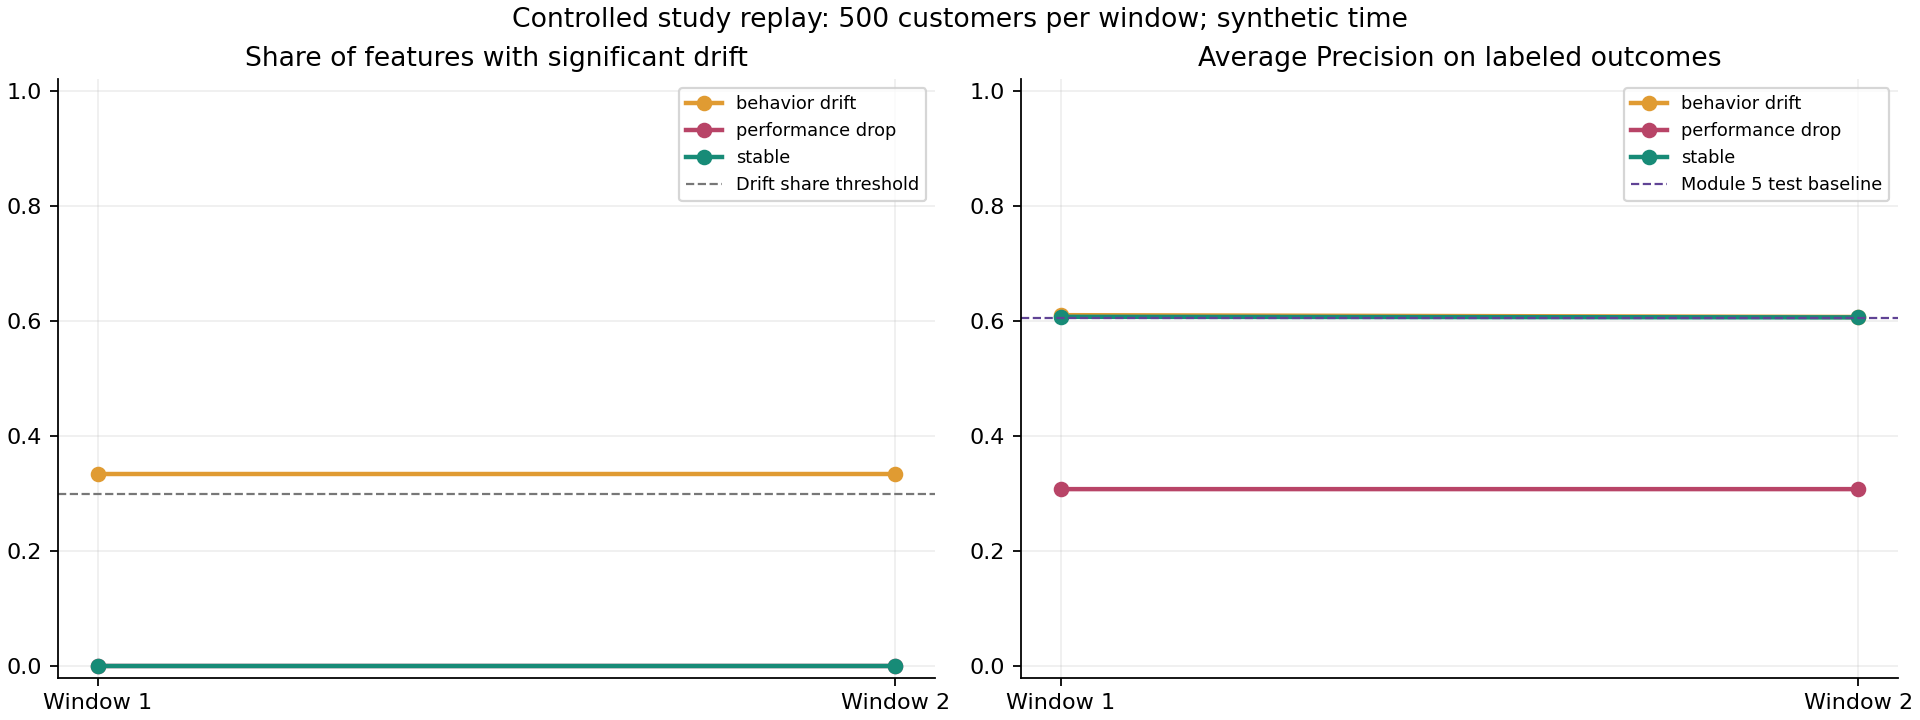

In [2]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
colors = {"stable":"#178b77","behavior_drift":"#e09b32","performance_drop":"#b84467"}
for scenario, group in summary.groupby("scenario"):
    group = group.sort_values("window")
    for axis, metric in zip(axes, ("drift_share", "average_precision")):
        axis.plot(range(1,len(group)+1), group[metric], marker="o", label=scenario.replace("_"," "), color=colors[scenario])
        axis.set_xticks([1,2], ["Window 1", "Window 2"])
        axis.set_ylim(-.02,1.02)
        axis.grid(alpha=.2)
axes[0].set_title("Share of features with significant drift")
axes[0].axhline(.3, color="#777", linestyle="--", label="Drift share threshold")
axes[1].set_title("Average Precision on labeled outcomes")
axes[1].axhline(reports[0]["performance"]["baseline"]["PR_AUC"], color="#604395", linestyle="--", label="Module 5 test baseline")
for axis in axes:
    axis.legend(fontsize=8)
fig.suptitle("Controlled study replay: 500 customers per window; synthetic time")
plt.show()


## Interpretation

The stable cohort stays close to its baseline. Behavioral drift moves one third of the monitored features and triggers review after two windows; Average Precision remains near its baseline, illustrating that feature drift is not itself proof of quality loss. The adversarial-label scenario leaves feature distributions stable but reduces Average Precision to about 0.308, causing a retraining recommendation after two eligible windows.

No future label is inferred from a prediction. Live predictions have a 90-day outcome horizon and remain in a waiting state until ground truth is supplied. Importing delayed labels refreshes their original prediction windows and adjacent trigger evidence. Single-class and insufficient samples are explicitly marked.

## Operating and retraining procedure

Configure DATABASE_URL and MONITORING_ADMIN_TOKEN outside source control. Prepare Module 5 artifacts, migrate the private monitoring schema, and start FastAPI. The React monitoring page reads the same aggregate report JSON used by downloadable HTML/JSON exports. PostgreSQL preserves history across process restart/redeploy. The API-only scheduler runs from the fork default branch and evaluates live/snapshot batches; replay requires an explicit operator action.

On a trigger: inspect data and labels, build a candidate, evaluate independently, compare to the current version, then obtain an owner decision for deployment or rollback. Rules do not replace a model automatically.

See docs/module-7-monitoring.md for API calls, role/RLS setup, threshold configuration, CI, scheduler, retention and live acceptance checks.